# Earphone cable winder reconstruction
Millimetres; original coordinates preserved. Three separate bodies. Target: sampled bidirectional Hausdorff ≤0.5 mm, volume within 1%, matching Euler number. The compound channel and latch transitions use measured section lofts; this is an approximate redesign, not a recovery of the original CAD history.

## 0. Setup

In [ ]:
from pathlib import Path
import json, hashlib
import numpy as np
import trimesh
import build123d
from build123d import *
import matplotlib.pyplot as plt
from IPython.display import display, Image

OUT = Path.cwd()
if not (OUT / 'reference.stl').exists():
    OUT = OUT / 'CableWinder'
SRC = OUT / 'reference.stl'
TOL_MM = 0.5
VOLUME_TOL = 0.01
RUN_DETECT = False
RUN_MESH_IMPORT = False
RUN_REMEASURE = False
RUN_MODEL = True
RUN_VERIFY = True
SHOW_RECON = True
print('build123d:', build123d.__version__)
HAS_DETECT = hasattr(build123d, 'detect_primitives')
print('detect_primitives:', HAS_DETECT)
print('Reference SHA256:', hashlib.sha256(SRC.read_bytes()).hexdigest())
if SHOW_RECON:
    from ocp_vscode import show, set_defaults, Camera
    set_defaults(reset_camera=Camera.KEEP)


build123d: 0.13.1.dev12+ge22d34dae
detect_primitives: True
Reference SHA256: 879e82e19ad094eeaeeda4887ccd2bc7ba241f77676b8a7a8cfb75777fb6ba47


## 1. Triage

In [2]:
m = trimesh.load(SRC, force='mesh')
bodies = sorted(m.split(only_watertight=False), key=lambda b: -b.volume)
def mesh_info(mesh):
    return dict(faces=len(mesh.faces),vertices=len(mesh.vertices),watertight=mesh.is_watertight,
      winding_ok=mesh.is_winding_consistent,volume=float(mesh.volume),area=float(mesh.area),
      bounds=mesh.bounds.tolist(),extents=mesh.extents.tolist(),euler=int(mesh.euler_number))
triage = mesh_info(m)
triage['bodies'] = [mesh_info(b) for b in bodies]
display(triage)
assert m.is_watertight and m.is_winding_consistent


{'faces': 46428,
 'vertices': 23216,
 'watertight': True,
 'winding_ok': True,
 'volume': 23792.04052630121,
 'area': 18672.779672099256,
 'bounds': [[-177.2311553955078, -9.942569732666016, 0.0],
  [-112.13215637207031, 55.1534309387207, 16.600000381469727]],
 'extents': [65.0989990234375, 65.09600067138672, 16.600000381469727],
 'euler': 2,
 'bodies': [{'faces': 16958,
   'vertices': 8479,
   'watertight': True,
   'winding_ok': True,
   'volume': 17629.236952522555,
   'area': 9845.137253519952,
   'bounds': [[-171.12904357910156, -4.896969318389893, 0.0],
    [-117.18204498291016, 50.103031158447266, 16.600000381469727]],
   'extents': [53.946998596191406, 55.00000047683716, 16.600000381469727],
   'euler': 0},
  {'faces': 27206,
   'vertices': 13603,
   'watertight': True,
   'winding_ok': True,
   'volume': 4676.720655977691,
   'area': 7903.979591553158,
   'bounds': [[-177.2311553955078, -9.942569732666016, 0.0],
    [-112.13215637207031, 55.1534309387207, 16.600000381469727]],

Assessment: moderately difficult mechanical assembly. Core, retaining ring, and pin have Euler numbers 0, 0, 2. No mesh repairs. The asymmetric channel and ring opening prevent global symmetry reduction. Z is the stacking axis. Retain the native XY placement and Z=0 floor.

## 2. Orientation

In [3]:
TRANSFORM = np.eye(4)  # identity: no recentering, rotation, or scale conversion
def symmetric_about(mesh, axis, count=1000):
    pts,_ = trimesh.sample.sample_surface(mesh,count,seed=42)
    pts[:,axis] = 2*mesh.bounds[:,axis].mean()-pts[:,axis]
    d = trimesh.proximity.closest_point(mesh,pts)[1]
    return dict(max=float(d.max()),mean=float(d.mean()))
symmetry = {str(i): {name:symmetric_about(b,j) for j,name in enumerate('XYZ')}
            for i,b in enumerate(bodies)}
display(symmetry)


{'0': {'X': {'max': 7.462376718768931, 'mean': 0.7497987381069666},
  'Y': {'max': 8.718832145970937, 'mean': 0.9212789301273732},
  'Z': {'max': 9.607286599172618, 'mean': 0.5259294644886914}},
 '1': {'X': {'max': 4.813176611055058, 'mean': 0.10208198659173758},
  'Y': {'max': 4.117992015013906, 'mean': 0.11073965422582814},
  'Z': {'max': 2.6742920967578296, 'mean': 0.005227019770208658}},
 '2': {'X': {'max': 0.0006619995378827249, 'mean': 3.272734467297783e-05},
  'Y': {'max': 0.001605271086407573, 'mean': 0.00024440731520366827},
  'Z': {'max': 0.0006621399218663417, 'mean': 3.0815081828488744e-05}}}

## 3. Structure

0 {'X': 4130, 'Y': 4110, 'Z': 510} axis aligned area share 0.4211417031525678


{0.0: 1880.8687467189586,
 16.6: 1332.3386255643713,
 0.6: 775.7120236065239,
 0.2: 56.822917507608,
 16.0: 2.942668996665816}

1 {'X': 6471, 'Y': 5401, 'Z': 1919} axis aligned area share 0.08745963276170671


{16.6: 338.2697077318704, 0.0: 315.7418795873933, 2.6: 6.242390641627935}

2 {'X': 267, 'Y': 228, 'Z': 8} axis aligned area share 0.3337514037837743


{0.0: 144.51661917701858, 16.6: 144.51661917701858}

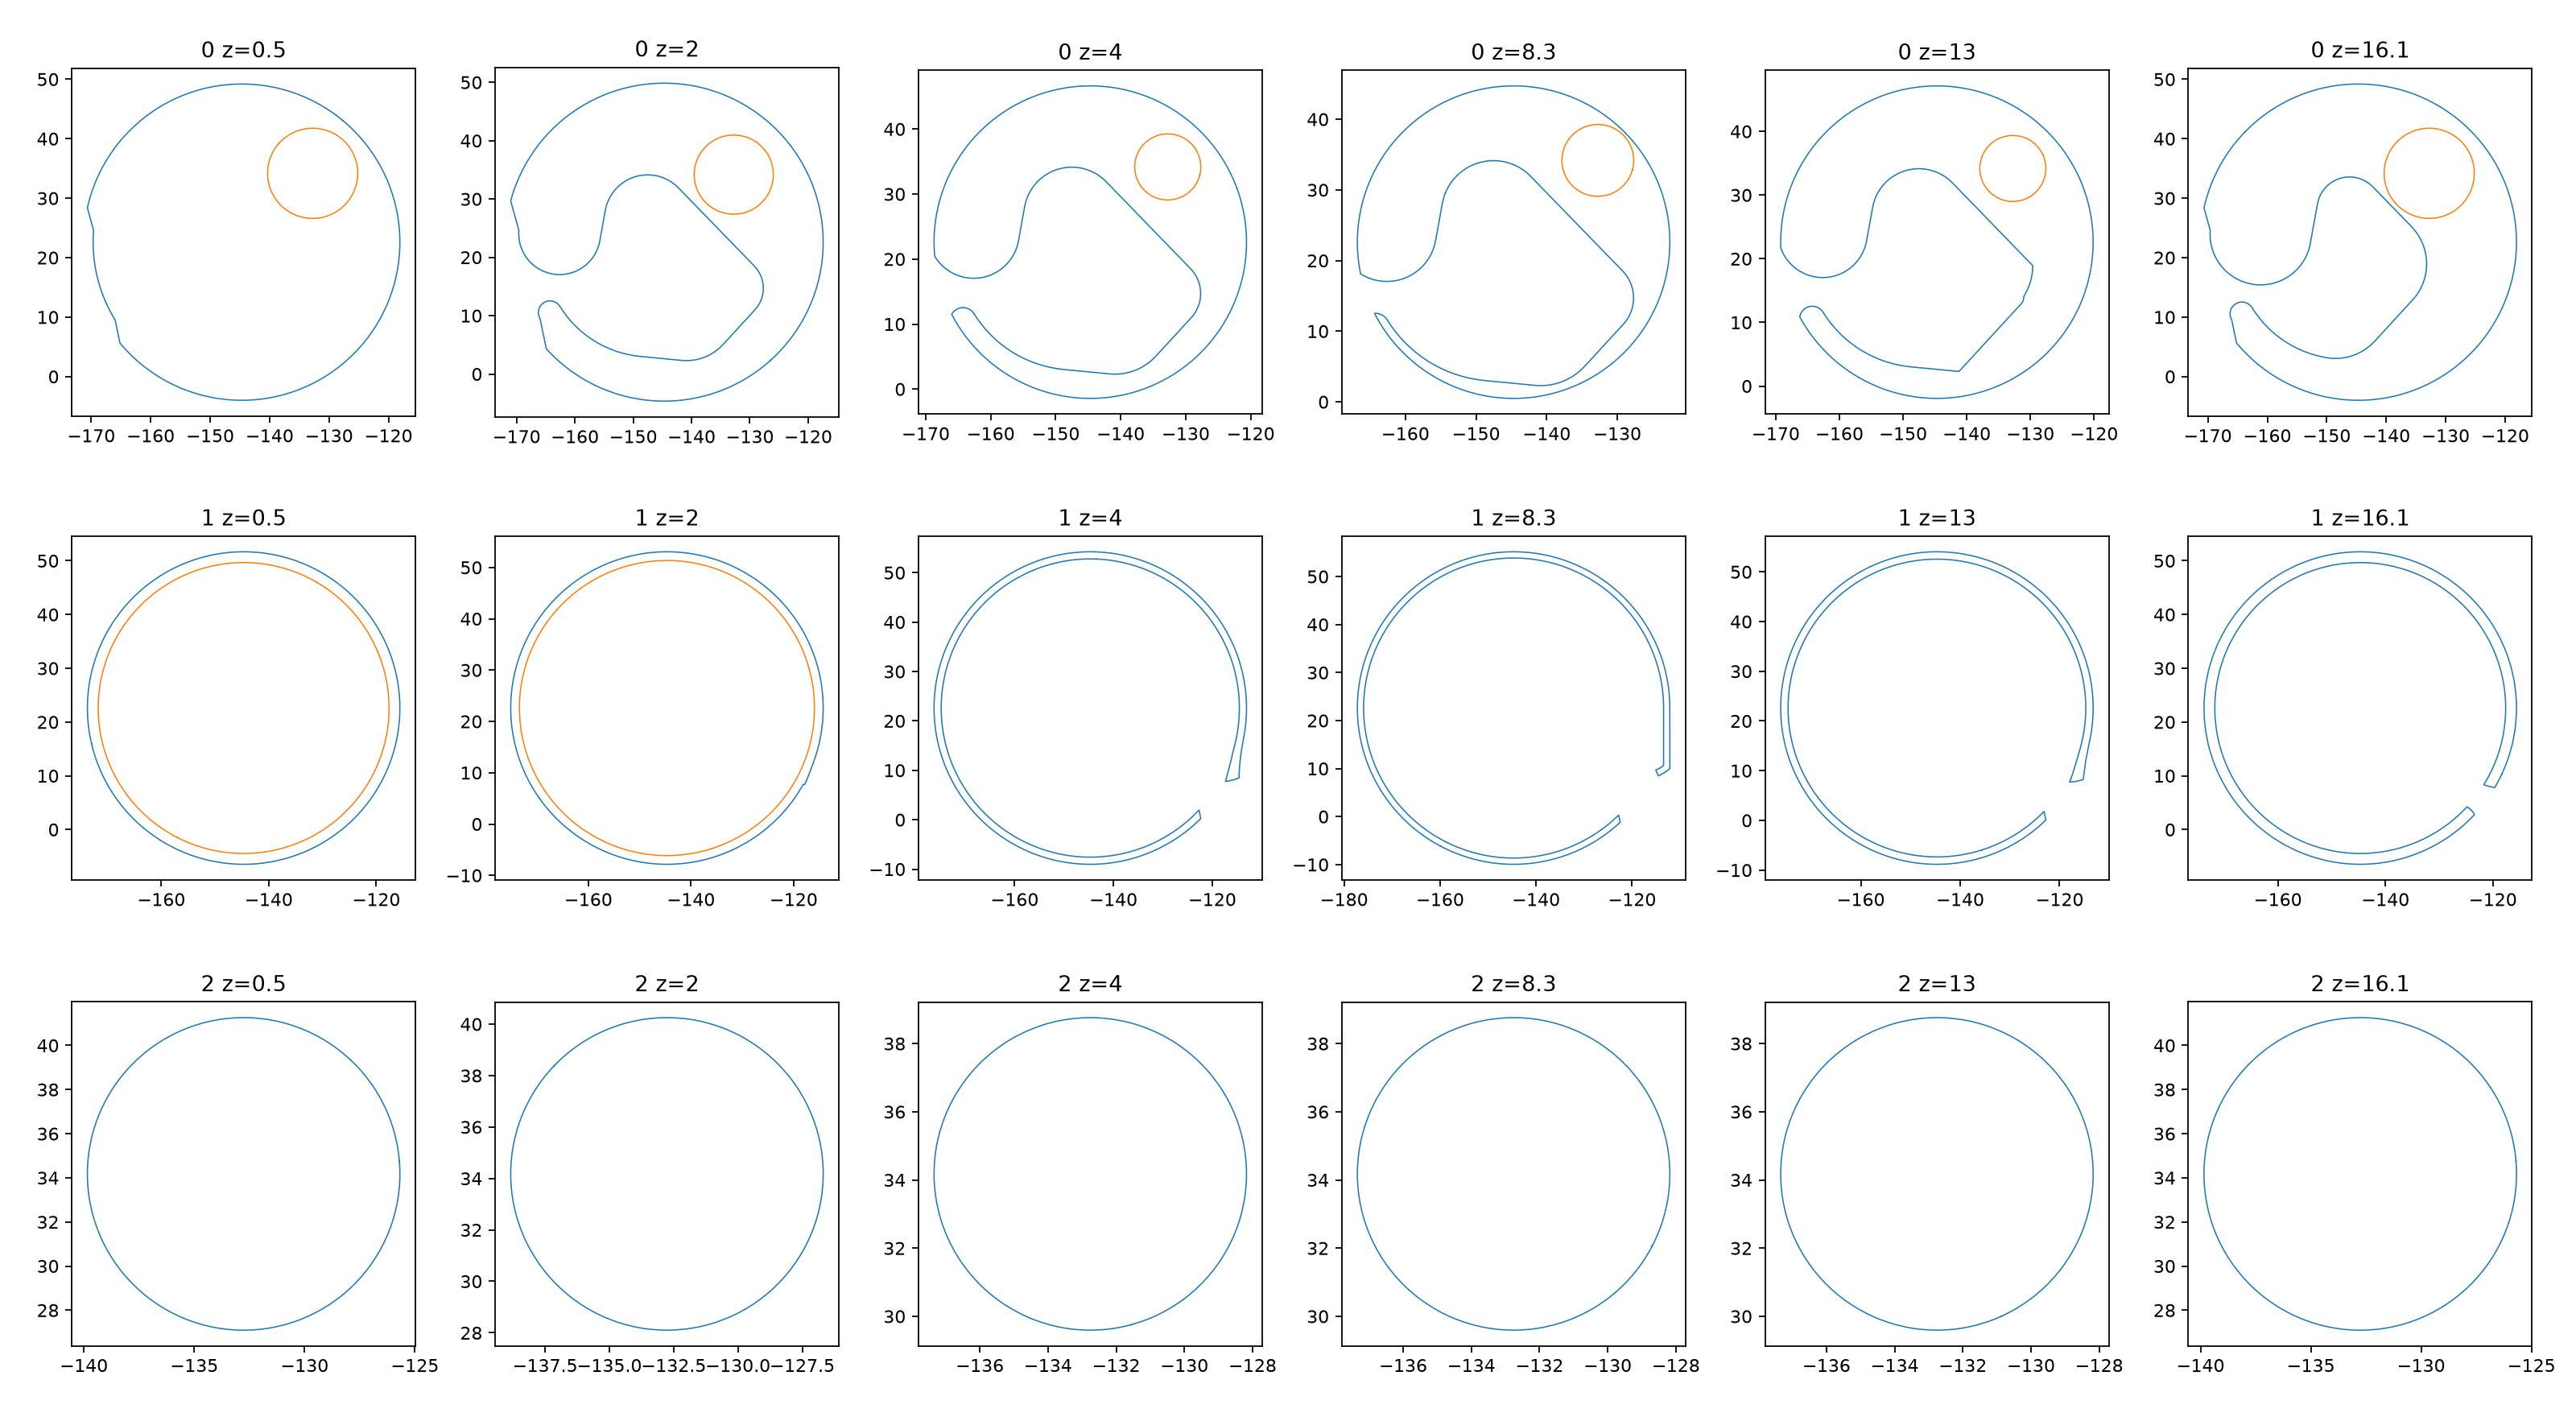

In [4]:
for i,b in enumerate(bodies):
    n=b.face_normals
    aligned = np.abs(n).max(axis=1) > 0.999
    levels = {name:len(np.unique(b.vertices[:,j].round(3))) for j,name in enumerate('XYZ')}
    horizontal = np.abs(n[:,2]) > .99999
    z=np.round(b.triangles_center[:,2],3)
    checksums={float(h):float(b.area_faces[horizontal & (z==h)].sum()) for h in np.unique(z[horizontal])}
    print(i,levels,'axis aligned area share',float(b.area_faces[aligned].sum()/b.area))
    display(dict(sorted(checksums.items(),key=lambda item:-item[1])[:12]))
display(Image(filename=str(OUT/'sections.png')))


The core changes topology at Z=0.6 mm; the ring opening begins at Z=2.6 mm. Model these as separate additive features. The pin and core bore use radial stations with a straight waist, conical shoulders, head lands, and end bevels. Compound channel and latch boundaries are approximated by periodic section splines at 0.5 mm height spacing, with extra stations near topology changes.

## 4. Working section

In [5]:
WORKING_BREP = OUT / 'working_pin.brep'
if RUN_MESH_IMPORT or not WORKING_BREP.exists():
    importer = Mesher()
    working = importer.read(str(OUT/'reference_body_2.stl'))[0]
    export_brep(working,str(WORKING_BREP))
else:
    working = None  # avoid loading a faceted BREP unless detection is requested
print('Cached isolated pin:',WORKING_BREP.name)


Cached isolated pin: working_pin.brep


A half-pin split was attempted in MCP but returned an empty section. Detection therefore uses the isolated 2,264-face pin, reducing the full 46,428-face mesh by 95%. The cached BREP preserves this working region.

## 5. Primitive detection

In [6]:
if RUN_DETECT and HAS_DETECT:
    working=import_brep(str(WORKING_BREP))
    primitives,leftovers,code_lines=detect_primitives(working)
    detection=dict(code=code_lines,leftovers=len(leftovers),faces=len(working.faces()))
    (OUT/'primitive_detection.json').write_text(json.dumps(detection,indent=2))
elif not HAS_DETECT:
    print('detect_primitives unavailable: use levels, sections, and normals above.')
detection=json.loads((OUT/'primitive_detection.json').read_text())
print('leftovers:',detection['leftovers'],'of',detection['faces'])
print('\n'.join(detection['code'][-4:]))


leftovers: 993 of 2264
r18 = Plane.XY * Pos(-139.542, 27.3927) * Rectangle(13.5632, 13.568, align=Align.MIN)
c19 = Plane.XY.offset(0.299999) * Pos(-132.756, 34.182) * Face.extrude(Circle(7.08401).edge(), (0, 0, 16))
c20 = Plane.XY.offset(3.49289) * Pos(-132.757, 34.177) * Face.extrude(Circle(4.58484).edge(), (0, 0, 9.61421))
r21 = Plane.XY.offset(16.6) * Pos(-139.542, 27.3927) * Rectangle(13.5632, 13.568, align=Align.MIN)


Detection is a report only. It recognized the main pin cylinders but left 43.9% unclassified and emitted spurious tilted cylinders. None of its code fragments is used in the final model.

## 6. Parameters

In [7]:
# Dimensions in millimetres. Reference height 16.6000004.
height = 16.6
reference_height = 16.6
body_center_x = -144.682
body_center_y = 22.603
pin_center_x = -132.756
pin_center_y = 34.177
xy_scale = 1.0
core_floor_thickness = 0.6
core_reference_radius = 27.5
core_embed_inset = 0.2
ring_bridge_height = 2.6
bridge_bore_relief = 0.2  # local join clearance; avoids a nearly coincident annular ledge
pin_waist_radius = 4.584
pin_head_radius = 7.084
pin_end_radius = 6.784
pin_end_chamfer = 0.3
pin_head_shoulder = 1.0
pin_waist_start = 3.5
bore_waist_radius = 5.084
bore_head_radius = 7.584
bore_end_radius = 7.884
bore_end_chamfer = 0.3
bore_head_shoulder = 1.2
bore_waist_start = 3.7
cutter_margin = 1.0
profile_approximation_tolerance = 0.02
profile_segments = 16
profile_span_samples = 16
feature_overlap = 0.15
latch_cleanup_offset_x = 28.782
latch_cleanup_offset_y = -1.753
latch_cleanup_width = 1.4
latch_cleanup_length = 2.1
latch_cleanup_depth = 0.3


PROFILES=json.loads((OUT/'measured_profiles.json').read_text())
if RUN_REMEASURE:
    # Rebuild measured profile cache from the reference, then reload it.
    import runpy
    runpy.run_path(str(OUT/'prepare_sections.py'))
    PROFILES=json.loads((OUT/'measured_profiles.json').read_text())


Each profile record names its Z station and contains measured XY control points. Global width/height and feature dimensions are editable; the profile coordinates remain explicit approximation controls. No transform is applied. Dimensions and assumptions are listed in report.md.

## 7. Model

In [8]:
def section_face(record, z_override=None, radial_inset=0.0):
    z = record['z'] if z_override is None else z_override
    section_scale=xy_scale*(1-radial_inset/core_reference_radius)
    xyz = [(body_center_x+(x-body_center_x)*section_scale,
            body_center_y+(y-body_center_y)*section_scale,
            z*height/reference_height) for x,y in record['points']]
    # Approximate the faceted section with short, low-degree spline spans.
    vectors=[Vector(*p) for p in xyz]
    count=len(vectors)
    edges=[]
    for segment in range(profile_segments):
        start=segment*count//profile_segments
        end=(segment+1)*count//profile_segments
        points=[vectors[j%count] for j in range(start,end+1)]
        smooth=Edge.make_spline_approx(points,
                     tol=profile_approximation_tolerance,min_deg=3,max_deg=3)
        fit_points=[smooth@(j/profile_span_samples) for j in range(profile_span_samples+1)]
        edges.append(Edge.make_spline(fit_points,
                     parameters=[float(j) for j in range(profile_span_samples+1)]))
    return Face(Wire(edges))

def profile_loft(records, bottom=None, top=None, bottom_inset=0.0):
    faces = [section_face(rec,
             bottom if j==0 and bottom is not None else
             top if j==len(records)-1 and top is not None else None,
             radial_inset=bottom_inset if j==0 else 0.0)
             for j,rec in enumerate(records)]
    with BuildPart() as feature:
        loft(sections=faces, ruled=True)
    return feature.part

def revolved_feature(radial_stations, cx, cy):
    # radius-height coordinates in a local XZ sketch, then revolve about Z.
    pts=[(0,radial_stations[0][1])]+radial_stations+[(0,radial_stations[-1][1])]
    plane=Plane(origin=(cx,cy,0),x_dir=(1,0,0),z_dir=(0,-1,0))
    with BuildPart() as feature:
        with BuildSketch(plane):
            with BuildLine():
                Polyline(*pts,close=True)
            make_face()
        revolve(axis=Axis((cx,cy,0),(0,0,1)))
    return feature.part

def build_model():
    core_floor=profile_loft(PROFILES['core_floor'],top=core_floor_thickness)
    core_hook=profile_loft(PROFILES['core_hook'],bottom=core_floor_thickness-feature_overlap,
                            bottom_inset=core_embed_inset)
    with BuildPart() as core_build:
        insert(core_floor)
        insert(core_hook)
    core_blank=core_build.part
    bore_stations=[(bore_end_radius,-cutter_margin),
        (bore_end_radius,0), (bore_head_radius,bore_end_chamfer),
        (bore_head_radius,bore_head_shoulder),
        (bore_waist_radius,bore_waist_start),
        (bore_waist_radius,height-bore_waist_start),
        (bore_head_radius,height-bore_head_shoulder),
        (bore_head_radius,height-bore_end_chamfer),
        (bore_end_radius,height),(bore_end_radius,height+cutter_margin)]
    bore=revolved_feature(bore_stations,pin_center_x,pin_center_y)
    with BuildPart() as core_build:
        insert(core_blank)
        insert(bore,mode=Mode.SUBTRACT)
    core=core_build.part

    ring_floor=profile_loft(PROFILES['ring_floor_outer'],top=ring_bridge_height)
    inner=[(r+bridge_bore_relief if j==len(PROFILES['ring_floor_inner'])-1 else r,
            ring_bridge_height if j==len(PROFILES['ring_floor_inner'])-1 else z)
           for j,(z,r) in enumerate(PROFILES['ring_floor_inner'])]
    inner=[(inner[0][0],-cutter_margin)]+inner+[(inner[-1][0],ring_bridge_height+cutter_margin)]
    ring_bore=revolved_feature(inner,body_center_x,body_center_y)
    with BuildPart() as ring_base:
        insert(ring_floor)
        insert(ring_bore,mode=Mode.SUBTRACT)
    ring_open=profile_loft(PROFILES['ring_open'],bottom=ring_bridge_height-feature_overlap)
    with BuildPart() as ring_build:
        insert(ring_base.part)
        insert(ring_open)
    ring=ring_build.part
    with BuildPart() as ring_finish:
        insert(ring)
        with Locations((body_center_x+latch_cleanup_offset_x,
                        body_center_y+latch_cleanup_offset_y,height-latch_cleanup_depth)):
            Box(latch_cleanup_width,latch_cleanup_length,latch_cleanup_depth+cutter_margin,
                align=(Align.CENTER,Align.CENTER,Align.MIN),mode=Mode.SUBTRACT)
    ring=ring_finish.part

    pin_stations=[(pin_end_radius,0),(pin_head_radius,pin_end_chamfer),
        (pin_head_radius,pin_head_shoulder),(pin_waist_radius,pin_waist_start),
        (pin_waist_radius,height-pin_waist_start),
        (pin_head_radius,height-pin_head_shoulder),
        (pin_head_radius,height-pin_end_chamfer),(pin_end_radius,height)]
    pin=revolved_feature(pin_stations,pin_center_x,pin_center_y)
    return core,ring,pin


if RUN_MODEL or not (OUT/'rebuilt.brep').exists():
    core,ring,pin=build_model()
else:
    cached=import_brep(str(OUT/'rebuilt.brep'))
    core,ring,pin=sorted(cached.solids(),key=lambda s:-s.volume)
result=Compound(children=[core,ring,pin])
from OCP.BRepGProp import BRepGProp
from OCP.GProp import GProp_GProps
adaptive_volumes={}
for name,part in [('core',core),('ring',ring),('pin',pin)]:
    assert part.is_valid and part.volume>0, name
    properties=GProp_GProps()
    BRepGProp.VolumeProperties_s(part.wrapped,properties,1e-6,True,False)
    adaptive_volumes[name]=properties.Mass()
    print(name,'adaptive volume',properties.Mass(),'faces',len(part.faces()))
if SHOW_RECON: show(core,ring,pin,names=['core','ring','pin'])


core adaptive volume 17614.062067328865 faces 635


ring adaptive volume 4668.9678942198825 faces 645
pin adaptive volume 1487.9094141399164 faces 9


## 8. Verify

Removed numerical zero-area/duplicate triangles: 0


Comparing original surface to rebuild


Comparing rebuild surface to original


Checking mesh vertices


{
  "mean": 0.006286457279726407,
  "p95": 0.022136965672066005,
  "p99": 0.095931110030684,
  "max": 0.45363178951693683,
  "hausdorff": 0.46299229665602487,
  "vertex_max": [
    0.46299229665602487,
    0.3000011444091797
  ],
  "directional_max": [
    0.45363178951693683,
    0.3000011444091797
  ],
  "sample_count_per_direction": 50000,
  "volume_original": 23792.04052630121,
  "volume_rebuilt": 23766.024184192356,
  "volume_ratio": 0.9989065106845252,
  "extent_delta": [
    0.0149078369140625,
    -0.009455680847167969,
    0.0
  ],
  "euler": [
    2,
    2
  ],
  "watertight": [
    true,
    true
  ],
  "bodies": [
    3,
    3
  ],
  "body_euler": [
    [
      0,
      0,
      2
    ],
    [
      0,
      0,
      2
    ]
  ],
  "body_volumes": [
    [
      17629.236952522555,
      4676.720655977691,
      1486.0829178009783
    ],
    [
      17609.989423613948,
      4668.800915772733,
      1487.233844805679
    ]
  ],
  "reference_sha256": "879e82e19ad094eeaeeda488

{'mean': 0.006286457279726407,
 'p95': 0.022136965672066005,
 'p99': 0.095931110030684,
 'max': 0.45363178951693683,
 'hausdorff': 0.46299229665602487,
 'vertex_max': [0.46299229665602487, 0.3000011444091797],
 'directional_max': [0.45363178951693683, 0.3000011444091797],
 'sample_count_per_direction': 50000,
 'volume_original': 23792.04052630121,
 'volume_rebuilt': 23766.024184192356,
 'volume_ratio': 0.9989065106845252,
 'extent_delta': [0.0149078369140625, -0.009455680847167969, 0.0],
 'euler': [2, 2],
 'watertight': [True, True],
 'bodies': [3, 3],
 'body_euler': [[0, 0, 2], [0, 0, 2]],
 'body_volumes': [[17629.236952522555, 4676.720655977691, 1486.0829178009783],
  [17609.989423613948, 4668.800915772733, 1487.233844805679]],
 'reference_sha256': '879e82e19ad094eeaeeda4887ccd2bc7ba241f77676b8a7a8cfb75777fb6ba47',
 'rebuilt_sha256': '26b52079dcf72f9069b849b91b31371f95a3e55af27318087ec34e1fd26d3c4c',
 'bounds_original': [[-177.2311553955078, -9.942569732666016, 0.0],
  [-112.13215637

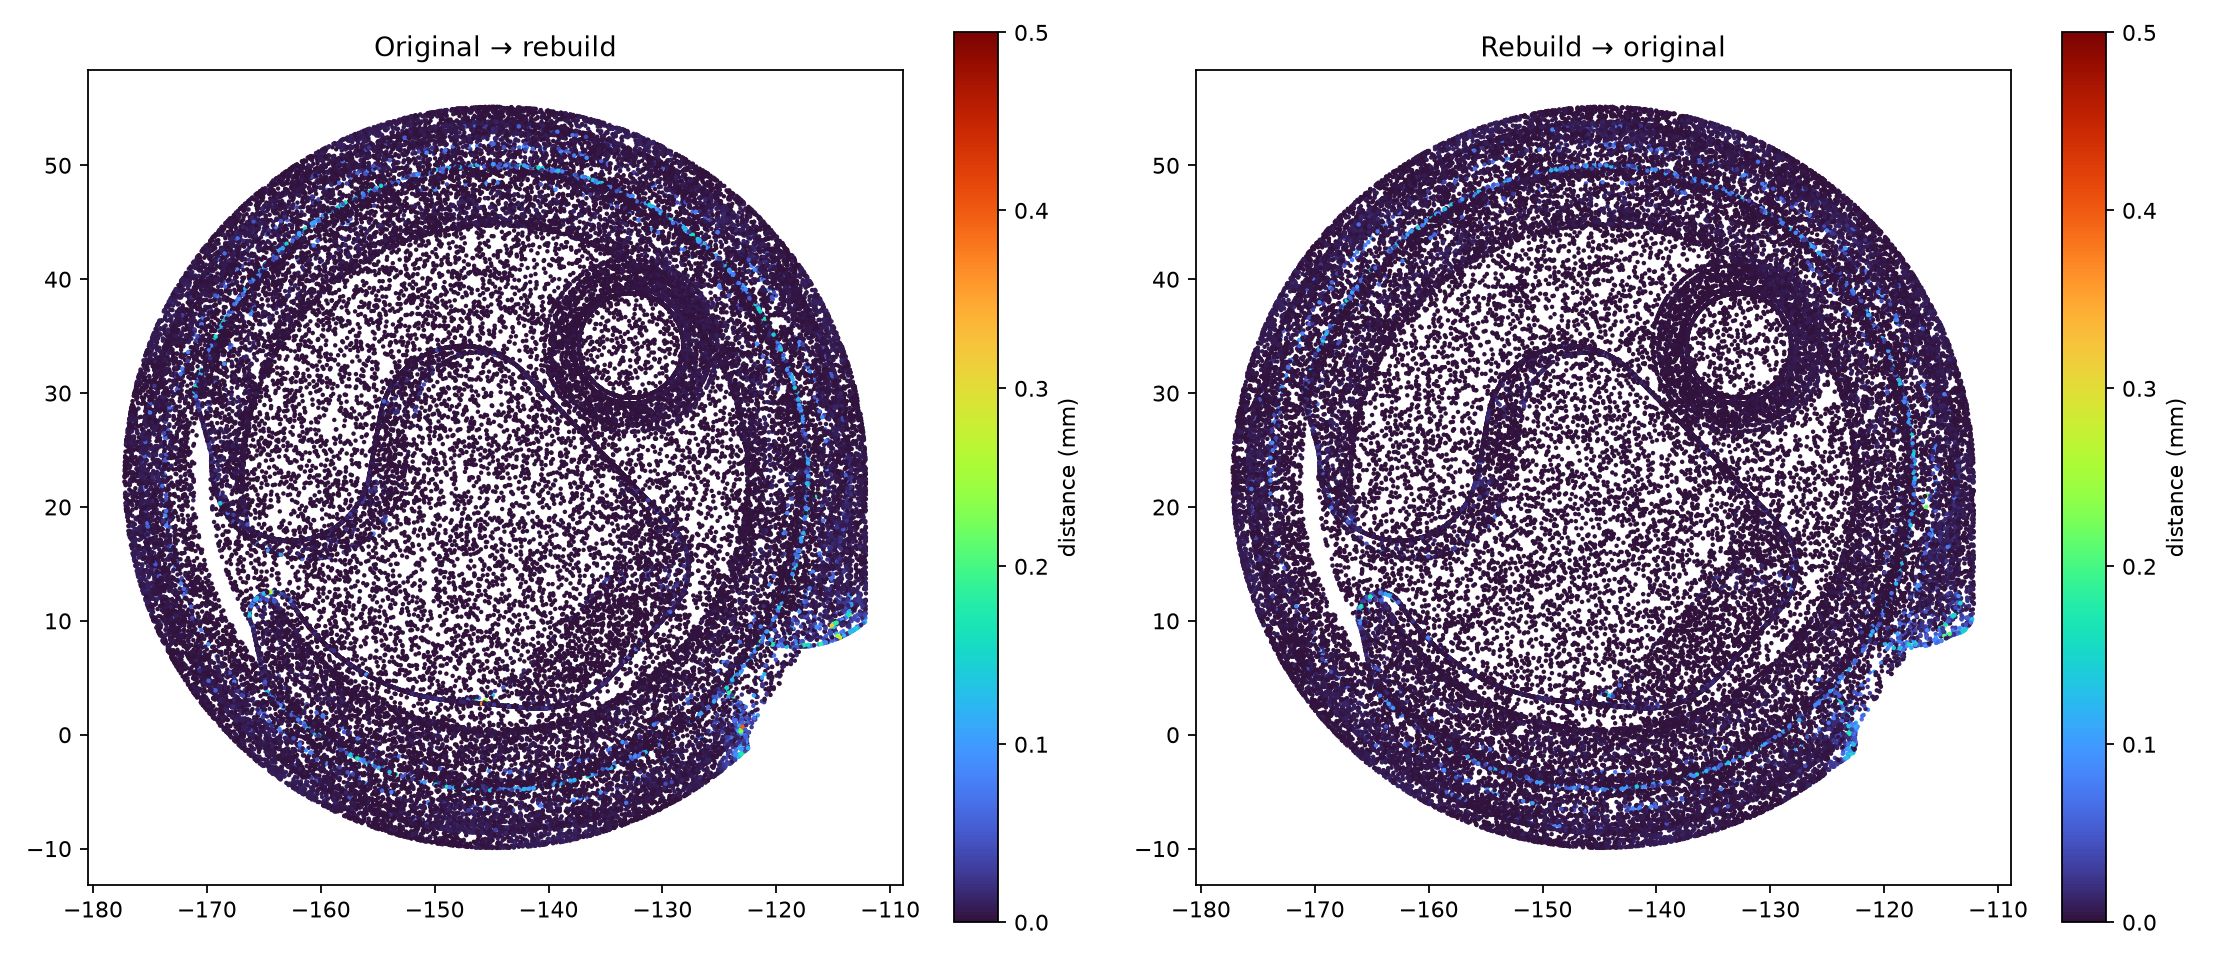

In [9]:
# Verification always examines the exported STL, rather than the live BREP.
export_stl(result,str(OUT/'rebuilt.stl'),tolerance=0.015,angular_tolerance=0.08)
exported=trimesh.load(OUT/'rebuilt.stl',force='mesh')
raw_face_count=len(exported.faces)
exported.update_faces(exported.nondegenerate_faces())
exported.update_faces(exported.unique_faces())
exported.remove_unreferenced_vertices()
exported.export(OUT/'rebuilt.stl')
print('Removed numerical zero-area/duplicate triangles:',raw_face_count-len(exported.faces))
if RUN_VERIFY:
    import sys
    if str(OUT) not in sys.path:sys.path.insert(0,str(OUT))
    from verify_mesh import verify
    verification=verify(SRC,OUT/'rebuilt.stl')
else:
    verification=json.loads((OUT/'verification.json').read_text())
    assert verification['reference_sha256']==hashlib.sha256(SRC.read_bytes()).hexdigest()
    assert verification['rebuilt_sha256']==hashlib.sha256((OUT/'rebuilt.stl').read_bytes()).hexdigest(), 'Cached verification is stale; set RUN_VERIFY=True'
display(verification)
verification['adaptive_brep_volumes']=adaptive_volumes
(OUT/'verification.json').write_text(json.dumps(verification,indent=2))
display(Image(filename=str(OUT/'deviation.png')))
assert verification['pass'], 'One or more acceptance criteria failed; inspect worst points.'


In [10]:
# Section overlays in native coordinates: reference solid versus export.
r=trimesh.load(OUT/'rebuilt.stl',force='mesh')
fig,axs=plt.subplots(1,4,figsize=(16,4))
for ax,z in zip(axs,[.4,2.8,8.3,16.2]):
    for mesh,color,label in [(m,'black','reference'),(r,'tomato','rebuild')]:
        sec=mesh.section(plane_normal=[0,0,1],plane_origin=[0,0,z])
        for pts in sec.discrete: ax.plot(pts[:,0],pts[:,1],color=color,lw=.7,label=label)
    ax.set_aspect('equal');ax.set_title(f'Z={z} mm')
fig.tight_layout();fig.savefig(OUT/'section_overlays.png',dpi=160);plt.show()


C:\Users\zachg\AppData\Local\Temp\ipykernel_23612\388949306.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();fig.savefig(OUT/'section_overlays.png',dpi=160);plt.show()


Distance statistics are deterministic sampled estimates: 50,000 surface points per direction plus every mesh vertex. They are not a certified continuous Hausdorff upper bound. See report.md for achieved values, local corrections, and remaining approximation error.

## 9. Export

In [11]:
assert verification['pass']
export_step(result,str(OUT/'rebuilt.step'))
export_brep(result,str(OUT/'rebuilt.brep'))
print('STEP, STL, and BREP exported in',OUT)


STEP, STL, and BREP exported in D:\Projects\Build123d\CableWinder
